# Dream in Orbit: An AI That Simulates a Satellite

## 1. Satellite Data Exploration

### 1.1 Project Overview

This project aims to develop an AI-based world model capable of learning satellite operational behavior from historical data and simulating its electricity consumption over time.

The primary objective is to predict satellite electricity consumption on an hourly basis over an entire year, using operational schedules and historical satellite measurements.

### 1.2 Objectives of Exploratory Data Analysis

- Examine the structure and organization of the satellite datasets.
- Identify the available operational and power-related variables.
- Investigate data quality, missing values, and temporal coverage.
- Explore relationships between satellite operations and electricity consumption.
- Identify useful features for subsequent machine learning models.

In [1]:
# Section 1.3 — Verify Dataset Directory Structure

from pathlib import Path

# Define the project root and dataset directory
project_root = Path.cwd()
data_dir = project_root / "data"

# Display the current working directory
print("Project directory:", project_root)
print("Dataset directory:", data_dir)

# Verify the dataset folders and list available CSV files
for year in ["annee1", "annee2"]:
    year_dir = data_dir / year

    print(f"\n{year}:")

    if year_dir.exists():
        csv_files = sorted(year_dir.glob("*.csv"))

        for file in csv_files:
            print(f"  - {file.name}")

        print(f"Total CSV files: {len(csv_files)}")
    else:
        print("Directory not found!")

Project directory: C:\Users\DAMISA\Desktop\DAMISA\ECE M2\M2 Sem 1\FABLAB\Dream Orbit\Dream-in-Orbit-an-AI-that-simulates-a-satellite
Dataset directory: C:\Users\DAMISA\Desktop\DAMISA\ECE M2\M2 Sem 1\FABLAB\Dream Orbit\Dream-in-Orbit-an-AI-that-simulates-a-satellite\data

annee1:
  - dmop.csv
  - evtf.csv
  - ftl.csv
  - ltdata.csv
  - power.csv
  - saaf.csv
Total CSV files: 6

annee2:
  - dmop.csv
  - evtf.csv
  - ftl.csv
  - ltdata.csv
  - power.csv
  - saaf.csv
Total CSV files: 6


### 1.4 Dataset Structure and Initial Inspection

The satellite dataset consists of two annual datasets, `annee1` and `annee2`, each containing six CSV files.

This section examines the structure of the available datasets, including their dimensions, column names, and data types.

The initial inspection will help identify the information available for modelling satellite electricity consumption and determine the preprocessing requirements for subsequent analysis.

In [2]:
# Section 1.4 — Inspect Satellite Dataset Structure

import pandas as pd

# Inspect the structure of each CSV file without loading
# the complete datasets into memory
dataset_summary = []

for year in ["annee1", "annee2"]:
    year_dir = data_dir / year

    for file in sorted(year_dir.glob("*.csv")):
        try:
            sample = pd.read_csv(file, nrows=5)

            dataset_summary.append({
                "Year": year,
                "Dataset": file.name,
                "Columns": len(sample.columns),
                "Column Names": ", ".join(sample.columns),
                "Status": "Successfully read"
            })

        except Exception as e:
            dataset_summary.append({
                "Year": year,
                "Dataset": file.name,
                "Columns": None,
                "Column Names": None,
                "Status": str(e)
            })

# Create and display the summary table
df_dataset_summary = pd.DataFrame(dataset_summary)

display(df_dataset_summary)

,Year,Dataset,Columns,Column Names,Status
0,annee1,dmop.csv,2,"ut_ms, subsystem",Successfully read
1,annee1,evtf.csv,2,"ut_ms, description",Successfully read
2,annee1,ftl.csv,4,"utb_ms, ute_ms, type, flagcomms",Successfully read
3,annee1,ltdata.csv,7,"ut_ms, sunmars_km, earthmars_km, sunmarseartha...",Successfully read
4,annee1,power.csv,34,"ut_ms, NPWD2372, NPWD2401, NPWD2402, NPWD2451,...",Successfully read
5,annee1,saaf.csv,5,"ut_ms, sa, sx, sy, sz",Successfully read
6,annee2,dmop.csv,2,"ut_ms, subsystem",Successfully read
7,annee2,evtf.csv,2,"ut_ms, description",Successfully read
8,annee2,ftl.csv,4,"utb_ms, ute_ms, type, flagcomms",Successfully read
9,annee2,ltdata.csv,7,"ut_ms, sunmars_km, earthmars_km, sunmarseartha...",Successfully read


### 1.5 Initial Dataset Observations

The initial inspection confirms that the satellite dataset contains 12 CSV files distributed equally across two observation years.

Each year contains six datasets with matching column counts and column names, suggesting a consistent data structure across both years.

The datasets contain operational information, event descriptions, time-related variables, satellite geometry, and power measurements.

The `power.csv` dataset contains 34 columns, making it an important candidate for investigating satellite electricity consumption.

Most datasets include a timestamp variable named `ut_ms`, which may provide a common temporal reference for integrating information from different satellite subsystems.

Further inspection is required to establish the exact meaning, units, temporal coverage, and quality of these variables.

In [3]:
# Section 1.6 — Preview Satellite Dataset Records

# Inspect the first five records of each dataset from Year 1
for file in sorted((data_dir / "annee1").glob("*.csv")):
    print(f"\nDataset: {file.name}")
    display(pd.read_csv(file, nrows=5))


Dataset: dmop.csv


,ut_ms,subsystem
0,1219363211000,AXXX301A
1,1219364909000,AAAAF20C1
2,1219364914000,AAAAF57A1
3,1219364919000,AAAAF23G1
4,1219364924000,AAAAF60A1



Dataset: evtf.csv


,ut_ms,description
0,1219364253000,MLG_LOS_05_/_RTLT_02373
1,1219364356000,NNO_AOS_00_/_RTLT_02373
2,1219365058000,MLG_LOS_02_/_RTLT_02373
3,1219365755000,NNO_AOS_05_/_RTLT_02373
4,1219367159000,NNO_AOS_10_/_RTLT_02374



Dataset: ftl.csv


,utb_ms,ute_ms,type,flagcomms
0,1219363213000,1219365494000,EARTH,False
1,1219365494000,1219369555000,EARTH,True
2,1219369555000,1219369619000,EARTH,False
3,1219369619000,1219370253000,SLEW,False
4,1219370253000,1219373093000,NADIR,False


... (2 outputs left out)


Dataset: power.csv


,ut_ms,NPWD2372,NPWD2401,NPWD2402,NPWD2451,NPWD2471,NPWD2472,NPWD2481,NPWD2482,NPWD2491,...,NPWD2792,NPWD2801,NPWD2802,NPWD2821,NPWD2851,NPWD2852,NPWD2871,NPWD2872,NPWD2881,NPWD2882
0,1219363209542,0.001821,0.001474,0.172173,0.005015,0.000714,0.000626,0.000665,0.001827,0.002016,...,0.000553,0.001474,0.156296,0.005547,0.004982,0.000501,0.000399,0.000714,0.006457,0.003227
1,1219363241537,0.002185,0.001769,0.177440,0.006019,0.000714,0.000751,0.000554,0.001827,0.430256,...,0.000553,0.001474,0.156296,0.005547,0.004982,0.000501,0.000499,0.000857,0.007748,0.003227
2,1219363273542,0.002185,0.001474,0.172173,0.005015,0.000571,0.000626,0.000554,0.001827,0.430256,...,0.000664,0.001474,0.161594,0.005547,0.004982,0.000501,0.000499,0.000571,0.006457,0.003227
3,1219363305537,0.001821,0.001474,0.172173,0.005015,0.000714,0.000751,0.000554,0.001827,0.424989,...,0.000664,0.001474,0.156296,0.006657,0.004982,0.000501,0.000598,0.000571,0.006457,0.003227
4,1219363337542,0.001821,0.001769,0.177440,0.005015,0.000714,0.000751,0.000554,0.001827,0.430256,...,0.000553,0.001474,0.161594,0.005547,0.004982,0.000501,0.000499,0.000714,0.006457,0.002582



Dataset: saaf.csv


,ut_ms,sa,sx,sy,sz
0,1219363213000,0.32,14.55,90.32,104.55
1,1219363235000,0.34,14.56,90.34,104.55
2,1219363295000,0.34,14.56,90.34,104.55
3,1219363355000,0.34,14.56,90.34,104.55
4,1219363415000,0.34,14.56,90.34,104.55


### 1.7 Identification of Satellite Variables

This section examines the complete variable names in the satellite datasets, with particular attention to the power measurements.

The objective is to identify candidate target variables and understand which measurements may be relevant to modelling satellite electricity consumption.

In [4]:
# Section 1.7 — Identify Satellite Power Variables

# Read only the column headers
power_columns = pd.read_csv(
    data_dir / "annee1" / "power.csv",
    nrows=0
).columns

print("SATELLITE POWER DATASET VARIABLES")
print("-" * 45)

for index, column in enumerate(power_columns, start=1):
    print(f"{index:02d}. {column}")

SATELLITE POWER DATASET VARIABLES
---------------------------------------------
01. ut_ms
02. NPWD2372
03. NPWD2401
04. NPWD2402
05. NPWD2451
06. NPWD2471
07. NPWD2472
08. NPWD2481
09. NPWD2482
10. NPWD2491
11. NPWD2501
12. NPWD2531
13. NPWD2532
14. NPWD2551
15. NPWD2552
16. NPWD2561
17. NPWD2562
18. NPWD2691
19. NPWD2692
20. NPWD2721
21. NPWD2722
22. NPWD2742
23. NPWD2771
24. NPWD2791
25. NPWD2792
26. NPWD2801
27. NPWD2802
28. NPWD2821
29. NPWD2851
30. NPWD2852
31. NPWD2871
32. NPWD2872
33. NPWD2881
34. NPWD2882


### 1.8 Statistical Examination of Satellite Power Measurements

This section investigates the numerical characteristics of the satellite power dataset.

The analysis focuses on:
- Identifying the data types of the power measurements.
- Examining minimum, maximum, mean, and standard deviation.
- Detecting missing values.
- Comparing measurements across satellite operating periods.

These observations will help identify potential prediction targets and determine whether additional information is required to interpret the measurements.

In [5]:
# Section 1.8 — Statistical Examination of Satellite Power Measurements

# Load the power dataset for the first year
df_power = pd.read_csv(data_dir / "annee1" / "power.csv")

# Exclude the timestamp from measurement statistics
power_measurements = df_power.drop(columns=["ut_ms"])

# Generate statistical summary
power_stats = power_measurements.describe().T

# Include missing value counts and data types
power_stats["Missing Values"] = power_measurements.isna().sum()
power_stats["Data Type"] = power_measurements.dtypes.astype(str)

# Select relevant statistics
power_stats = power_stats[
    ["count", "mean", "std", "min", "max",
     "Missing Values", "Data Type"]
]

print("SATELLITE POWER MEASUREMENT STATISTICS")
print("-" * 50)

display(power_stats)

SATELLITE POWER MEASUREMENT STATISTICS
--------------------------------------------------


,count,mean,std,min,max,Missing Values,Data Type
NPWD2372,1830121.0,0.114662,1.707532e-01,0.001457,0.379161,0,float64
NPWD2401,1830121.0,0.001527,1.394552e-04,0.001179,0.001769,0,float64
NPWD2402,1830121.0,0.175334,2.598973e-03,0.161639,0.182707,0,float64
NPWD2451,1830121.0,0.644853,8.402739e-01,0.004012,2.215750,0,float64
NPWD2471,1830121.0,0.000739,6.972305e-05,0.000571,0.000857,0,float64
NPWD2472,1830121.0,0.000648,5.845207e-05,0.000500,0.000751,0,float64
NPWD2481,1830121.0,0.001154,1.449714e-02,0.000444,0.404634,0,float64
NPWD2482,1830121.0,0.001894,1.728026e-04,0.001462,0.002192,0,float64
NPWD2491,1830121.0,0.192073,2.126879e-01,0.001613,0.435523,0,float64
NPWD2501,1830121.0,0.005201,4.736798e-04,0.004022,0.006033,0,float64


### 1.8 Statistical Examination of Satellite Power Measurements

This section investigates the numerical characteristics of the satellite power dataset.

The analysis focuses on:
- Identifying the data types of the power measurements.
- Examining minimum, maximum, mean, and standard deviation.
- Detecting missing values.
- Comparing measurements across satellite operating periods.

These observations will help identify potential prediction targets and determine whether additional information is required to interpret the measurements.

In [6]:
# Section 1.8 — Statistical Examination of Satellite Power Measurements

# Load the power dataset for the first year
df_power = pd.read_csv(data_dir / "annee1" / "power.csv")

# Exclude the timestamp from measurement statistics
power_measurements = df_power.drop(columns=["ut_ms"])

# Generate statistical summary
power_stats = power_measurements.describe().T

# Include missing value counts and data types
power_stats["Missing Values"] = power_measurements.isna().sum()
power_stats["Data Type"] = power_measurements.dtypes.astype(str)

# Select relevant statistics
power_stats = power_stats[
    ["count", "mean", "std", "min", "max",
     "Missing Values", "Data Type"]
]

print("SATELLITE POWER MEASUREMENT STATISTICS")
print("-" * 50)

display(power_stats)

SATELLITE POWER MEASUREMENT STATISTICS
--------------------------------------------------


,count,mean,std,min,max,Missing Values,Data Type
NPWD2372,1830121.0,0.114662,1.707532e-01,0.001457,0.379161,0,float64
NPWD2401,1830121.0,0.001527,1.394552e-04,0.001179,0.001769,0,float64
NPWD2402,1830121.0,0.175334,2.598973e-03,0.161639,0.182707,0,float64
NPWD2451,1830121.0,0.644853,8.402739e-01,0.004012,2.215750,0,float64
NPWD2471,1830121.0,0.000739,6.972305e-05,0.000571,0.000857,0,float64
NPWD2472,1830121.0,0.000648,5.845207e-05,0.000500,0.000751,0,float64
NPWD2481,1830121.0,0.001154,1.449714e-02,0.000444,0.404634,0,float64
NPWD2482,1830121.0,0.001894,1.728026e-04,0.001462,0.002192,0,float64
NPWD2491,1830121.0,0.192073,2.126879e-01,0.001613,0.435523,0,float64
NPWD2501,1830121.0,0.005201,4.736798e-04,0.004022,0.006033,0,float64


### 1.9 Temporal Structure and Sampling Frequency

This section examines the temporal characteristics of the satellite power dataset.

The analysis determines the observation period, sampling frequency,
timestamp consistency, and potential irregularities in data collection.

Understanding these characteristics is essential for time-series
analysis and the development of reliable satellite energy prediction models.

In [7]:
# Section 1.9 — Temporal Structure and Sampling Frequency

# Convert Unix timestamps in milliseconds to datetime
power_timestamps = pd.to_datetime(
    df_power["ut_ms"], unit="ms", utc=True
)

# Calculate observation period
start_date = power_timestamps.min()
end_date = power_timestamps.max()
observation_duration = end_date - start_date

# Calculate sampling intervals in seconds
sampling_intervals = (
    df_power["ut_ms"].sort_values().diff().dropna() / 1000
)

# Summarize temporal characteristics
temporal_summary = pd.DataFrame({
    "Metric": [
        "Start Date",
        "End Date",
        "Observation Duration",
        "Total Observations",
        "Median Sampling Interval (seconds)",
        "Minimum Sampling Interval (seconds)",
        "Maximum Sampling Interval (seconds)",
        "Duplicate Timestamps"
    ],
    "Value": [
        str(start_date),
        str(end_date),
        str(observation_duration),
        len(df_power),
        sampling_intervals.median(),
        sampling_intervals.min(),
        sampling_intervals.max(),
        df_power["ut_ms"].duplicated().sum()
    ]
})

display(temporal_summary)

,Metric,Value
0,Start Date,2008-08-22 00:00:09.542000+00:00
1,End Date,2010-07-09 23:59:36.556000+00:00
2,Observation Duration,686 days 23:59:27.014000
3,Total Observations,1830121
4,Median Sampling Interval (seconds),32.002
5,Minimum Sampling Interval (seconds),3.971
6,Maximum Sampling Interval (seconds),26143.996
7,Duplicate Timestamps,0


### 1.9.1 Interpretation of Temporal Characteristics

The temporal analysis of the satellite power dataset reveals the following findings:

1. **Observation period:** The dataset covers approximately 687 days, from August 22, 2008, to July 9, 2010, providing an extended period of satellite operational measurements.

2. **Sampling frequency:** The median sampling interval is approximately 32 seconds, indicating relatively frequent measurements suitable for time-series analysis.

3. **Sampling irregularities:** The minimum interval is 3.971 seconds, while the maximum interval reaches approximately 7.26 hours. These differences indicate that measurements were not recorded at perfectly uniform intervals.

4. **Timestamp uniqueness:** No duplicate timestamps were identified, indicating that each observation has a unique recorded time.

5. **Implications for predictive modeling:** The irregular sampling intervals must be considered when preparing the dataset for machine learning. Depending on the modeling approach, resampling, gap identification, or other temporal preprocessing techniques may be required.

**Conclusion:** The dataset provides extensive temporal coverage and relatively frequent measurements. However, its irregular sampling intervals require further investigation before developing time-series prediction models.

### 1.10 Investigation of Sampling Gaps

This section investigates irregularities in the temporal sampling
of the satellite power dataset.

The objectives are to:

- Examine the distribution of sampling intervals.
- Identify gaps exceeding the expected sampling interval.
- Quantify the frequency of significant sampling interruptions.
- Assess the implications of temporal irregularities for predictive modeling.

The findings will help determine whether temporal resampling or
additional preprocessing is necessary.

In [8]:
# Section 1.10 — Investigation of Sampling Gaps

# Define gap thresholds in seconds
gap_thresholds = [60, 120, 300, 600, 1800, 3600]

# Count intervals exceeding each threshold
gap_summary = pd.DataFrame({
    "Gap Threshold (seconds)": gap_thresholds,
    "Number of Gaps": [
        (sampling_intervals > threshold).sum()
        for threshold in gap_thresholds
    ]
})

# Calculate percentage of intervals exceeding each threshold
gap_summary["Percentage (%)"] = (
    gap_summary["Number of Gaps"]
    / len(sampling_intervals) * 100
).round(4)

print("SATELLITE SAMPLING GAP ANALYSIS")
print("-" * 45)

display(gap_summary)

# Display the 10 largest sampling gaps
print("\nTEN LARGEST SAMPLING GAPS (SECONDS)")
display(
    sampling_intervals.nlargest(10).reset_index(drop=True)
)

SATELLITE SAMPLING GAP ANALYSIS
---------------------------------------------


,Gap Threshold (seconds),Number of Gaps,Percentage (%)
0,60,20884,1.1411
1,120,93,0.0051
2,300,21,0.0011
3,600,20,0.0011
4,1800,14,0.0008
5,3600,12,0.0007



TEN LARGEST SAMPLING GAPS (SECONDS)


0    26143.996
1    21119.997
2    18944.015
3    15936.002
4    13087.981
5    12639.969
6    11135.999
7     9439.996
8     7871.998
9     6144.000
Name: ut_ms, dtype: float64

#### Interpretation of Sampling Gap Analysis

The sampling gap analysis indicates that the satellite power dataset exhibits relatively consistent temporal sampling, with approximately 98.86% of consecutive observations occurring within 60 seconds.

Only 93 intervals (0.0051%) exceed 120 seconds, suggesting that substantial sampling interruptions are uncommon.

However, 12 intervals exceed one hour, with the longest interruption lasting approximately 7.26 hours. These gaps may reflect temporary interruptions in data acquisition or transmission, although their causes cannot be confirmed from the available measurements.

Overall, the dataset demonstrates good temporal continuity. Nevertheless, significant sampling gaps should be considered during preprocessing and the development of time-series prediction models to prevent misleading temporal relationships.

### 1.11 — Visualization of Satellite Sampling Intervals

This section visualizes the distribution of time intervals between consecutive satellite power measurements.

The objective is to assess sampling consistency, identify the dominant measurement interval, and examine deviations from the expected sampling frequency.

The analysis builds on the sampling intervals calculated in Section 1.10, avoiding redundant data processing.

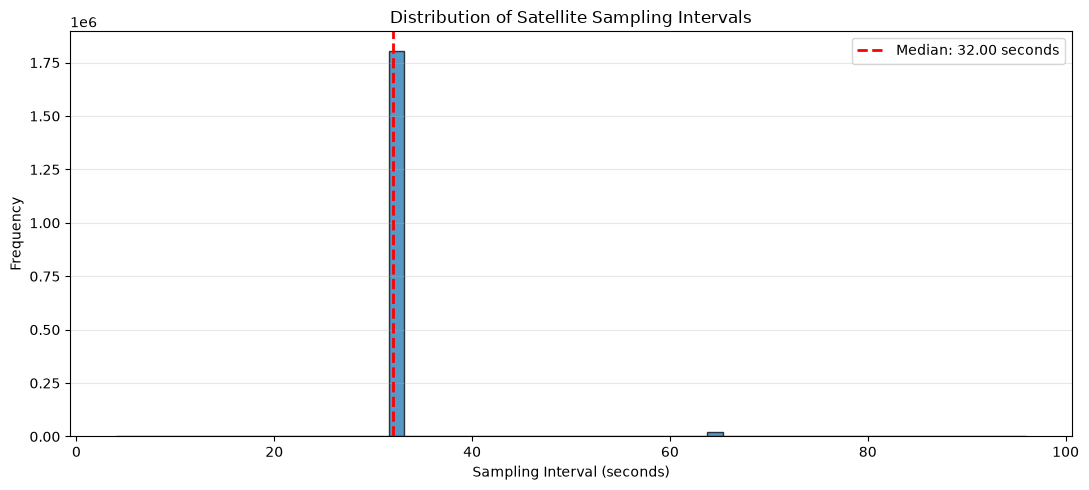

In [9]:

# Section 1.11 — Visualization of Satellite Sampling Intervals

import matplotlib.pyplot as plt

# Reuse sampling intervals calculated in Section 1.10
intervals = sampling_intervals.dropna()

# Focus on intervals of 120 seconds or less for readability
regular_intervals = intervals[intervals <= 120]

plt.figure(figsize=(11, 5))

plt.hist(
    regular_intervals,
    bins=60,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    intervals.median(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median: {intervals.median():.2f} seconds"
)

plt.title("Distribution of Satellite Sampling Intervals")
plt.xlabel("Sampling Interval (seconds)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


#### Interpretation of Satellite Sampling Interval Distribution

The histogram reveals a strongly concentrated distribution of satellite sampling intervals, with a dominant interval of approximately 32 seconds.

The median sampling interval of 32.002 seconds indicates that measurements are generally collected at a consistent frequency.

A smaller secondary peak occurs around 64 seconds, suggesting occasional intervals approximately twice the typical sampling duration. These may reflect skipped measurements or variations in data acquisition.

The results indicate that the dataset exhibits a largely regular temporal structure, making it suitable for further time-series analysis.

Nevertheless, irregular sampling intervals should be considered during preprocessing and predictive modeling to ensure that temporal relationships are accurately represented.

### 1.12 — Satellite Power Data Quality Assessment

This section evaluates the quality of satellite power measurements by identifying potentially anomalous values and examining their distribution.

The analysis focuses on:

- Detecting negative power measurements.
- Identifying zero-valued measurements.
- Examining unusually high observations using the interquartile range (IQR) method.
- Summarizing potential data-quality concerns across satellite power variables.

The objective is to identify measurements requiring further investigation before preprocessing and predictive modeling.

**Note:** Statistical outliers are not necessarily measurement errors. Extreme values may represent legitimate satellite operating conditions and should not be removed without further investigation.

In [15]:

# Section 1.12 — Satellite Power Data Quality Assessment

# Reuse existing satellite power measurements
power_columns = power_measurements.columns

# Calculate data quality indicators
quality_summary = pd.DataFrame({
    "Negative Values": (power_measurements < 0).sum(),
    "Zero Values": (power_measurements == 0).sum(),
    "Missing Values": power_measurements.isna().sum()
})

# Calculate IQR thresholds
Q1 = power_measurements.quantile(0.25)
Q3 = power_measurements.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count observations outside IQR thresholds
quality_summary["IQR Outliers"] = (
    (power_measurements < lower_bound) |
    (power_measurements > upper_bound)
).sum()

# Display data quality summary
print("SATELLITE POWER DATA QUALITY SUMMARY")
print("-" * 45)

display(quality_summary)


SATELLITE POWER DATA QUALITY SUMMARY
---------------------------------------------


,Negative Values,Zero Values,Missing Values,IQR Outliers
NPWD2372,0,0,0,0
NPWD2401,0,0,0,468941
NPWD2402,0,0,0,1
NPWD2451,0,0,0,0
NPWD2471,0,0,0,489447
NPWD2472,0,0,0,455873
NPWD2481,0,0,0,470819
NPWD2482,0,0,0,470788
NPWD2491,0,0,0,0
NPWD2501,0,0,0,460542


In [16]:

# Section 1.12 — Overall Data Quality Summary

total_observations = len(power_measurements)

# Summarize quality indicators across all variables
quality_overview = pd.DataFrame({
    "Metric": [
        "Total Power Variables",
        "Observations per Variable",
        "Variables with Negative Values",
        "Variables with Zero Values",
        "Variables with Missing Values",
        "Variables with IQR Outliers",
        "Highest IQR Outlier Count",
        "Variable with Most IQR Outliers"
    ],
    "Value": [
        len(power_columns),
        total_observations,
        (quality_summary["Negative Values"] > 0).sum(),
        (quality_summary["Zero Values"] > 0).sum(),
        (quality_summary["Missing Values"] > 0).sum(),
        (quality_summary["IQR Outliers"] > 0).sum(),
        quality_summary["IQR Outliers"].max(),
        quality_summary["IQR Outliers"].idxmax()
    ]
})

print("OVERALL SATELLITE POWER DATA QUALITY")
print("-" * 45)

display(quality_overview)


OVERALL SATELLITE POWER DATA QUALITY
---------------------------------------------


,Metric,Value
0,Total Power Variables,33
1,Observations per Variable,1830121
2,Variables with Negative Values,0
3,Variables with Zero Values,0
4,Variables with Missing Values,0
5,Variables with IQR Outliers,26
6,Highest IQR Outlier Count,783739
7,Variable with Most IQR Outliers,NPWD2851


### Interpretation — Satellite Power Data Quality Assessment

The data quality assessment examined 33 satellite power measurement variables, each containing 1,830,121 observations.

The results indicate excellent data completeness, with no missing, negative, or zero values identified across the power measurement variables.

However, 26 of the 33 variables (78.8%) contain observations classified as statistical outliers using the Interquartile Range (IQR) method.

The variable NPWD2851 recorded the highest number of outliers (783,739), representing approximately 42.82% of its observations.

These findings suggest that although the dataset is complete, several power measurement variables exhibit substantial variability or non-normal distributions.

Since satellite power consumption may fluctuate under different operating conditions, the identified outliers should not automatically be considered erroneous or removed.

Further investigation of the measurement distributions and operational characteristics is recommended before applying any outlier treatment.

**Conclusion:** The satellite power dataset is sufficiently complete for further exploratory analysis. However, the high frequency of statistical outliers in certain variables requires

## 1.13 — Satellite Power Distribution Analysis

### Objective

This section investigates the statistical distributions of satellite electrical power measurements to understand their variability, concentration, and potential deviations from normality.

The previous data quality assessment identified IQR outliers in 26 of the 33 power measurement variables. However, these observations may reflect legitimate satellite operating conditions rather than measurement errors.

The analysis will focus on:

- Visualizing the distributions of satellite power measurements.
- Identifying skewed, concentrated, or multimodal distributions.
- Investigating variables with unusually high IQR outlier counts.
- Assessing whether observed statistical outliers may be associated with different satellite operating states.

The findings will support subsequent exploratory analysis and inform appropriate preprocessing decisions for predictive modeling.

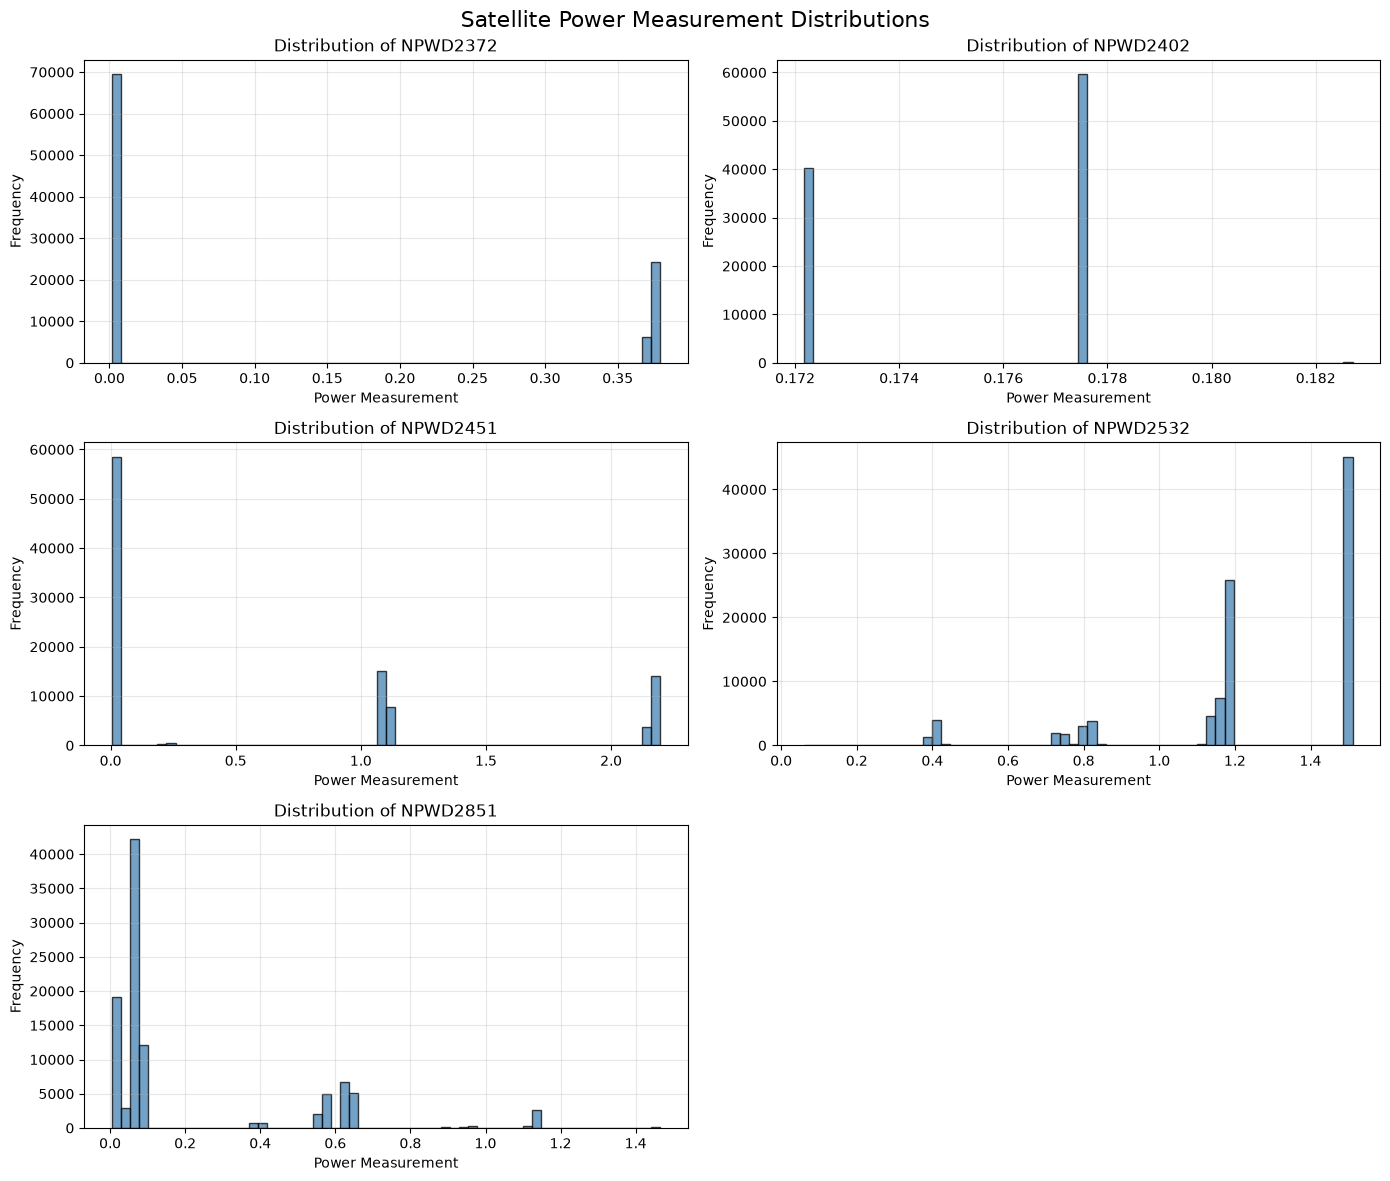

In [17]:
# Section 1.13 — Satellite Power Distribution Analysis

import matplotlib.pyplot as plt

# Select representative power measurement variables
selected_variables = [
    "NPWD2372",
    "NPWD2402",
    "NPWD2451",
    "NPWD2532",
    "NPWD2851"
]

# Use a reproducible sample for efficient visualization
distribution_sample = power_measurements[
    selected_variables
].sample(
    n=min(100000, len(power_measurements)),
    random_state=42
)

# Plot distributions
fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 12)
)

axes = axes.flatten()

for i, variable in enumerate(selected_variables):

    axes[i].hist(
        distribution_sample[variable],
        bins=60,
        color="steelblue",
        edgecolor="black",
        alpha=0.75
    )

    axes[i].set_title(f"Distribution of {variable}")
    axes[i].set_xlabel("Power Measurement")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(alpha=0.3)

# Remove unused subplot
fig.delaxes(axes[-1])

plt.suptitle(
    "Satellite Power Measurement Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Interpretation — Satellite Power Measurement Distributions

The distribution analysis reveals that the selected satellite power measurement variables exhibit non-normal distributions, with several showing distinct peaks and clusters.

NPWD2372 and NPWD2402 display two dominant measurement levels, while NPWD2451, NPWD2532, and NPWD2851 exhibit more complex multimodal distributions.

These patterns suggest that satellite electrical power measurements may vary between different operating conditions rather than fluctuating continuously around a single mean.

In particular, NPWD2851 exhibits several distinct measurement clusters, which may help explain its unusually high number of IQR outliers identified in Section 1.12.

The findings demonstrate that conventional statistical outlier detection methods may classify legitimate observations as outliers when applied to multimodal distributions.

**Conclusion:** The selected satellite power measurements exhibit distinct distribution patterns that may reflect variations in satellite subsystem operation. Consequently, statistical outliers should be investigated rather than automatically removed, particularly when preparing the dataset for predictive modeling.

## 1.14 — Satellite Power Correlation Analysis

### Objective

This section investigates the statistical relationships between the 33 satellite power measurement variables using Pearson correlation analysis.

The analysis aims to:

- Identify strongly positively and negatively correlated power measurements.
- Investigate potential relationships between satellite electrical subsystems.
- Detect highly correlated variables that may contain redundant information.
- Provide insights for subsequent feature engineering and predictive modeling.

Pearson correlation coefficients range from -1 to +1, where positive values indicate that two variables tend to increase together, negative values indicate that they tend to move in opposite directions, and values near zero indicate weak linear relationships.

Correlation does not necessarily imply causation, and the identified relationships will require further interpretation within the context of satellite operations.

In [19]:
# Section 1.14 — Satellite Power Correlation Analysis

# Calculate Pearson correlation coefficients
power_correlation = power_measurements.corr(method="pearson")

# Display correlation matrix dimensions
print("SATELLITE POWER CORRELATION ANALYSIS")
print("-" * 45)

print(f"Power variables: {power_correlation.shape[0]}")
print(f"Correlation matrix shape: {power_correlation.shape}")

# Preview a small section of the correlation matrix
display(power_correlation.iloc[:5, :5].round(3))

SATELLITE POWER CORRELATION ANALYSIS
---------------------------------------------
Power variables: 33
Correlation matrix shape: (33, 33)


,NPWD2372,NPWD2401,NPWD2402,NPWD2451,NPWD2471
NPWD2372,1.000,0.018,-0.000,0.016,0.000
NPWD2401,0.018,1.000,0.097,0.005,0.246
NPWD2402,-0.000,0.097,1.000,-0.007,0.150
NPWD2451,0.016,0.005,-0.007,1.000,0.009
NPWD2471,0.000,0.246,0.150,0.009,1.000


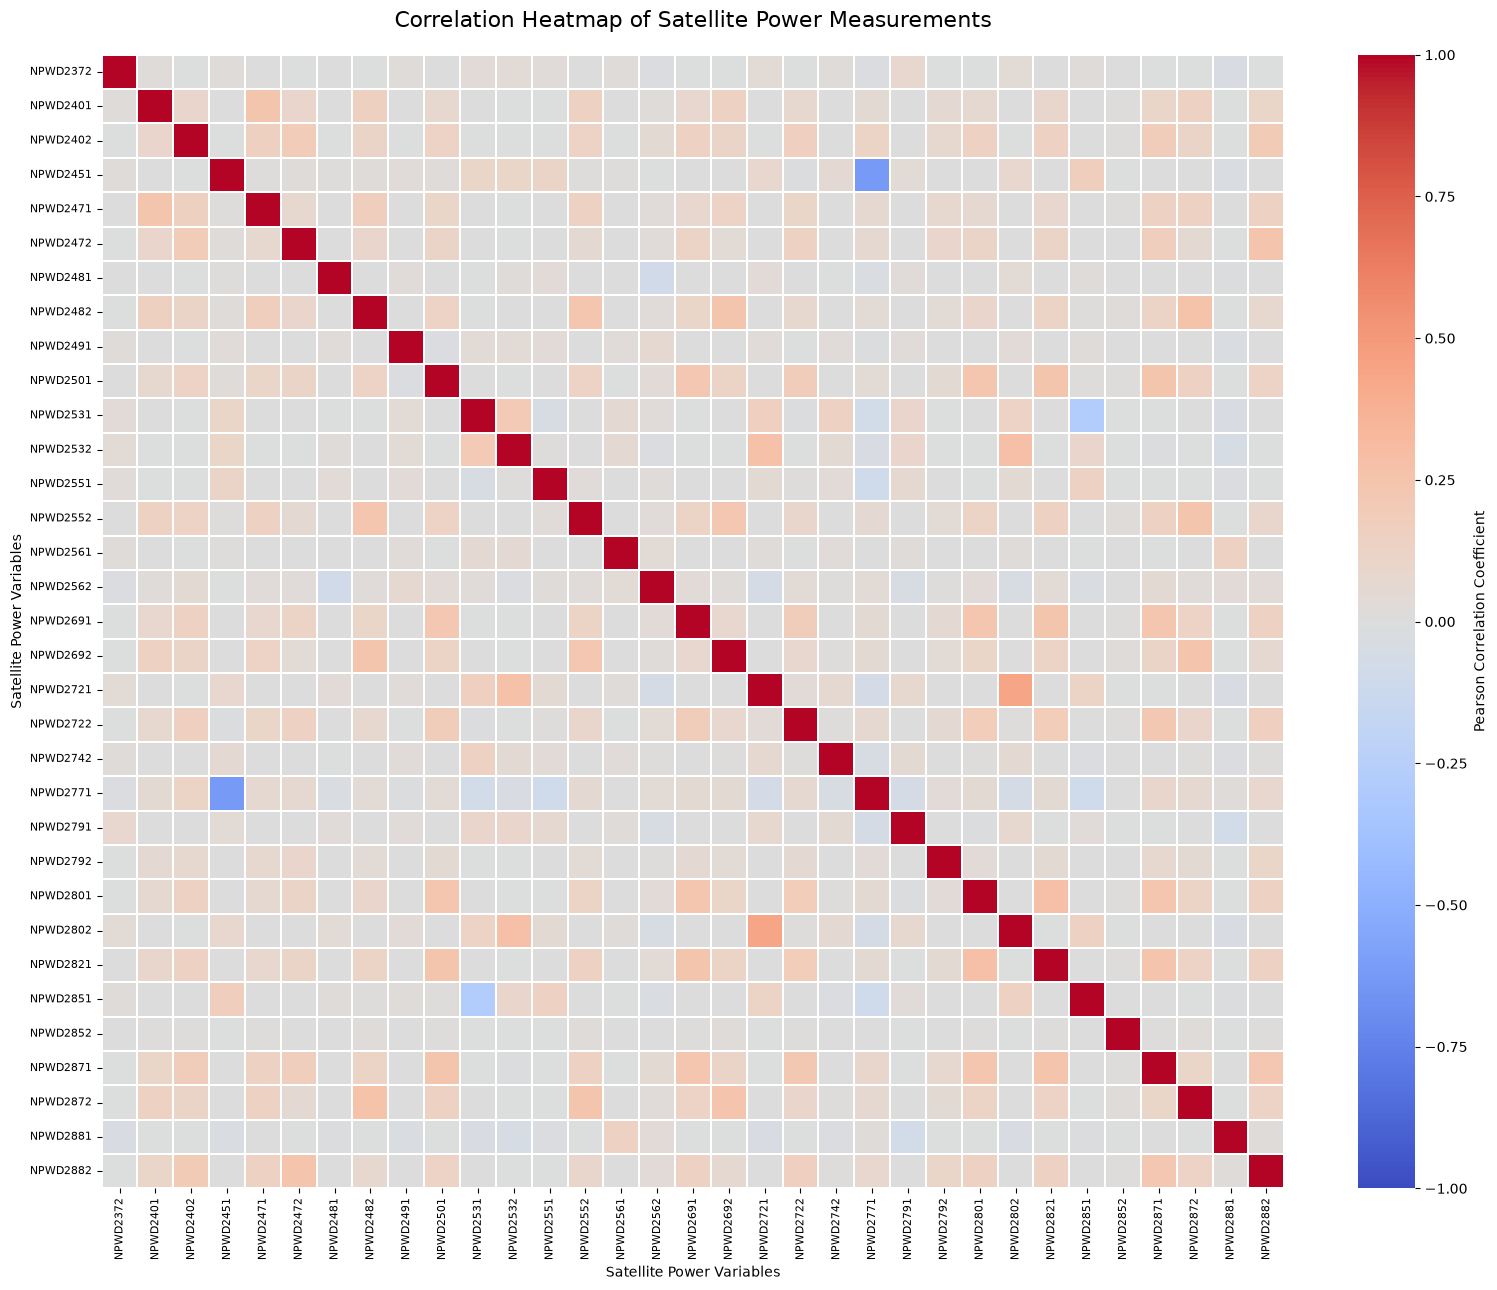

In [20]:
# Section 1.14 — Satellite Power Correlation Heatmap

import seaborn as sns
import matplotlib.pyplot as plt

# Create correlation heatmap
plt.figure(figsize=(16, 13))

sns.heatmap(
    power_correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    linewidths=0.2,
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)

plt.title(
    "Correlation Heatmap of Satellite Power Measurements",
    fontsize=16,
    pad=20
)

plt.xlabel("Satellite Power Variables")
plt.ylabel("Satellite Power Variables")

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.show()

### Interpretation of Satellite Power Correlation Analysis

The Pearson correlation heatmap illustrates the linear relationships
among the 33 satellite power measurement variables.

The majority of variable pairs exhibit weak correlations, suggesting
that many satellite power measurements capture relatively distinct
patterns of variation.

Some positive and negative correlations are visible, indicating that
certain measurements may exhibit related or opposing behavior.

The absence of large clusters of strongly correlated variables
suggests that widespread multicollinearity may be limited.

However, further numerical examination is necessary to identify
the strongest positive and negative relationships and assess
potential redundancy before developing predictive models.

In [21]:
# Section 1.14 — Strongest Satellite Power Correlations

import numpy as np

# Extract unique variable pairs from the existing correlation matrix
upper_triangle = power_correlation.where(
    np.triu(
        np.ones(power_correlation.shape, dtype=bool),
        k=1
    )
)

# Convert correlations into a ranked table
correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Variable 1",
    "Variable 2",
    "Correlation"
]

# Strongest positive relationships
strongest_positive = (
    correlation_pairs
    .sort_values("Correlation", ascending=False)
    .head(10)
)

# Strongest negative relationships
strongest_negative = (
    correlation_pairs
    .sort_values("Correlation", ascending=True)
    .head(10)
)

print("TOP 10 POSITIVE CORRELATIONS")
display(strongest_positive)

print("\nTOP 10 NEGATIVE CORRELATIONS")
display(strongest_negative)

TOP 10 POSITIVE CORRELATIONS


,Variable 1,Variable 2,Correlation
619,NPWD2721,NPWD2802,0.438880
818,NPWD2801,NPWD2821,0.278164
388,NPWD2532,NPWD2802,0.274872
381,NPWD2532,NPWD2721,0.272959
261,NPWD2482,NPWD2872,0.260996
887,NPWD2821,NPWD2871,0.256709
197,NPWD2472,NPWD2882,0.256318
591,NPWD2692,NPWD2872,0.256232
459,NPWD2552,NPWD2872,0.249980
326,NPWD2501,NPWD2871,0.248978



TOP 10 NEGATIVE CORRELATIONS


,Variable 1,Variable 2,Correlation
120,NPWD2451,NPWD2771,-0.617373
357,NPWD2531,NPWD2851,-0.285178
720,NPWD2771,NPWD2851,-0.099467
417,NPWD2551,NPWD2771,-0.096375
213,NPWD2481,NPWD2562,-0.092106
757,NPWD2791,NPWD2881,-0.080532
351,NPWD2531,NPWD2771,-0.079479
615,NPWD2721,NPWD2771,-0.064626
718,NPWD2771,NPWD2802,-0.062246
513,NPWD2562,NPWD2721,-0.061400


### Interpretation of Strongest Satellite Power Correlations

The correlation analysis identified the strongest positive and negative linear relationships among the 33 satellite power measurement variables.

The strongest positive correlation was observed between **NPWD2721 and NPWD2802 (r = 0.439)**, indicating a moderate positive linear relationship.

The strongest negative correlation occurred between **NPWD2451 and NPWD2771 (r = -0.617)**, suggesting a moderately strong inverse relationship.

Most remaining variable pairs exhibited weak correlations, indicating limited linear association among the satellite power measurements.

Furthermore, no pairwise correlation exceeded an absolute value of 0.8, suggesting that severe pairwise multicollinearity is unlikely to be a major concern.

These findings provide an initial understanding of relationships among satellite power measurements and will support subsequent feature analysis and predictive model development.

## 1.15 — Temporal Analysis of Satellite Power Measurements

### 1.15.1 — Satellite Power Measurements Over Time

This section investigates temporal variations in selected satellite power measurements.

Three variables (NPWD2721, NPWD2802, and NPWD2771) are selected based on the correlation analysis conducted in Section 1.14.

The analysis aims to:

- Examine changes in satellite power measurements over time.
- Identify temporal fluctuations and unusual measurement patterns.
- Compare the behavior of selected power variables.
- Provide insights for subsequent data preprocessing and predictive modeling.

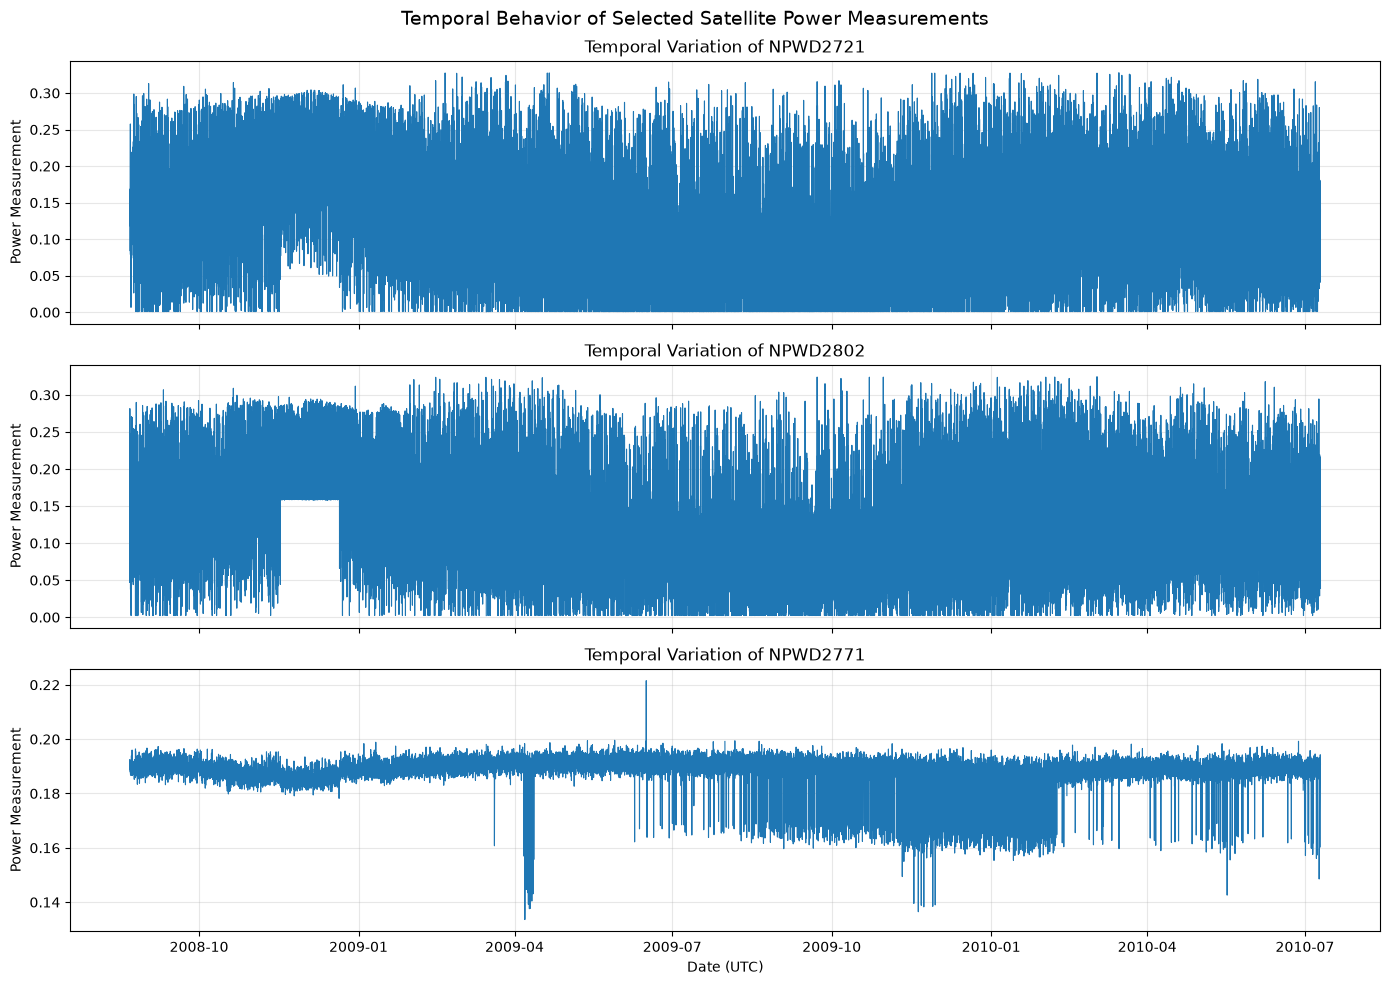

In [22]:

# Section 1.15.2 — Satellite Power Measurements Over Time

# Select variables identified during correlation analysis
selected_power_variables = [
    "NPWD2721",
    "NPWD2802",
    "NPWD2771"
]

# Convert satellite timestamps to datetime
power_time = pd.to_datetime(
    df_power["ut_ms"],
    unit="ms",
    utc=True
)

# Create hourly averages for clearer visualization
temporal_power = df_power[
    selected_power_variables
].copy()

temporal_power.index = power_time

hourly_power = temporal_power.resample("1h").mean()

# Plot temporal variations
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)

for ax, variable in zip(axes, selected_power_variables):
    ax.plot(
        hourly_power.index,
        hourly_power[variable],
        linewidth=0.8
    )

    ax.set_title(f"Temporal Variation of {variable}")
    ax.set_ylabel("Power Measurement")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date (UTC)")

plt.suptitle(
    "Temporal Behavior of Selected Satellite Power Measurements",
    fontsize=14
)

plt.tight_layout()
plt.show()


### Interpretation of Satellite Power Temporal Variations

The temporal analysis reveals distinct patterns in the selected satellite power measurements between August 2008 and July 2010.

**NPWD2721** exhibits substantial fluctuations throughout the observation period, indicating considerable temporal variability.

**NPWD2802** demonstrates a broadly similar pattern, including a distinct period of nearly constant measurements in late 2008. This similarity is consistent with the moderate positive correlation previously identified between NPWD2721 and NPWD2802.

**NPWD2771** displays comparatively stable measurements around 0.19, interrupted by occasional sharp deviations and periods of increased variability.

Overall, the results indicate that satellite power measurements exhibit different degrees of temporal stability. The observed fluctuations and unusual operating periods may reflect changes in satellite operating conditions or measurement behavior.

Further investigation is required to determine the underlying causes of these variations.

### 1.15.3 — Long-Term Trends in Satellite Power Measurements

To investigate long-term changes in satellite power measurements, monthly average values are calculated from the previously generated hourly dataset.

Monthly aggregation reduces short-term fluctuations and provides a clearer representation of longer-term measurement behavior.

The analysis focuses on the three previously selected variables (NPWD2721, NPWD2802, and NPWD2771), allowing direct comparison with the temporal patterns identified in Section 1.15.2.

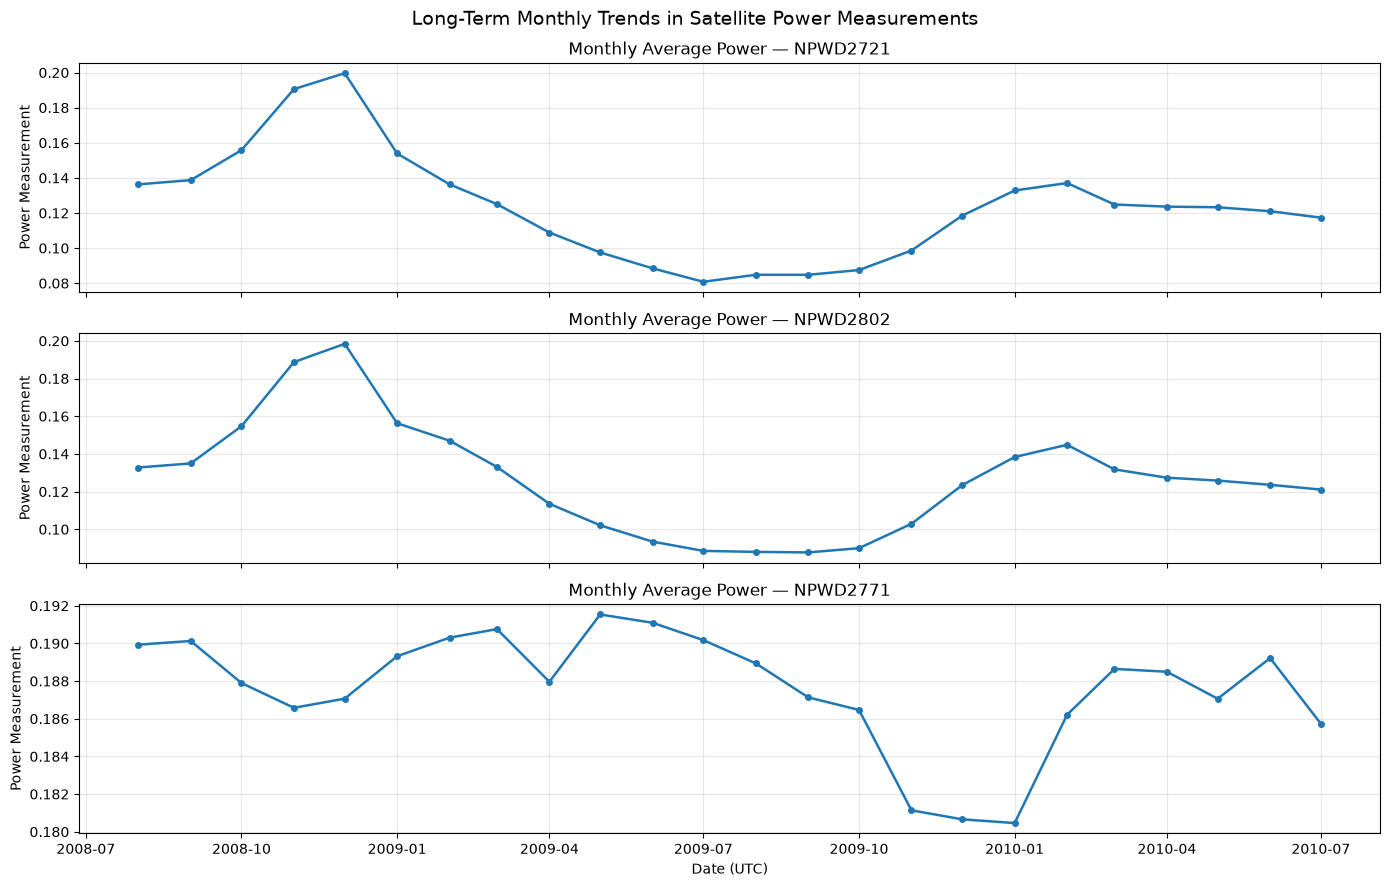

In [23]:

# Section 1.15.3 — Monthly Satellite Power Trends

# Reuse the hourly measurements from Section 1.15.2
monthly_power = hourly_power.resample("MS").mean()

# Visualize monthly trends
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 9),
    sharex=True
)

for ax, variable in zip(axes, selected_power_variables):
    ax.plot(
        monthly_power.index,
        monthly_power[variable],
        marker="o",
        linewidth=1.8,
        markersize=4
    )

    ax.set_title(f"Monthly Average Power — {variable}")
    ax.set_ylabel("Power Measurement")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date (UTC)")

plt.suptitle(
    "Long-Term Monthly Trends in Satellite Power Measurements",
    fontsize=14
)

plt.tight_layout()
plt.show()


### Interpretation of Long-Term Monthly Trends

The monthly trend analysis reveals distinct patterns across the three selected satellite power measurements.

NPWD2721 and NPWD2802 exhibit similar long-term behavior, characterized by increasing measurements toward the end of 2008, a sustained decline during 2009, and a subsequent recovery toward early 2010. These similarities suggest that both variables may be influenced by common operational or environmental factors.

In contrast, NPWD2771 demonstrates relatively stable monthly measurements throughout the observation period. However, a noticeable decline occurs between late 2009 and early 2010, followed by a recovery.

Overall, monthly aggregation reveals longer-term variations that were less apparent in the original high-frequency time-series plots. These findings highlight differences in measurement stability and suggest periods that may warrant further investigation.

The observed patterns do not, by themselves, establish their underlying physical causes.

### 1.15.4 — Monthly Variability and Measurement Stability

This section investigates the variability of satellite power measurements over time using monthly standard deviation.

Unlike the previous analysis, which examined changes in monthly average measurements, this analysis focuses on fluctuations within individual months.

The objectives are to:

- Evaluate the monthly variability of selected satellite power measurements.
- Identify periods of relatively stable and unstable measurement behavior.
- Compare variability patterns across selected power variables.
- Identify periods that may require further investigation.

A higher monthly standard deviation indicates greater variability in the measurements, while a lower standard deviation indicates more consistent values within the corresponding month.

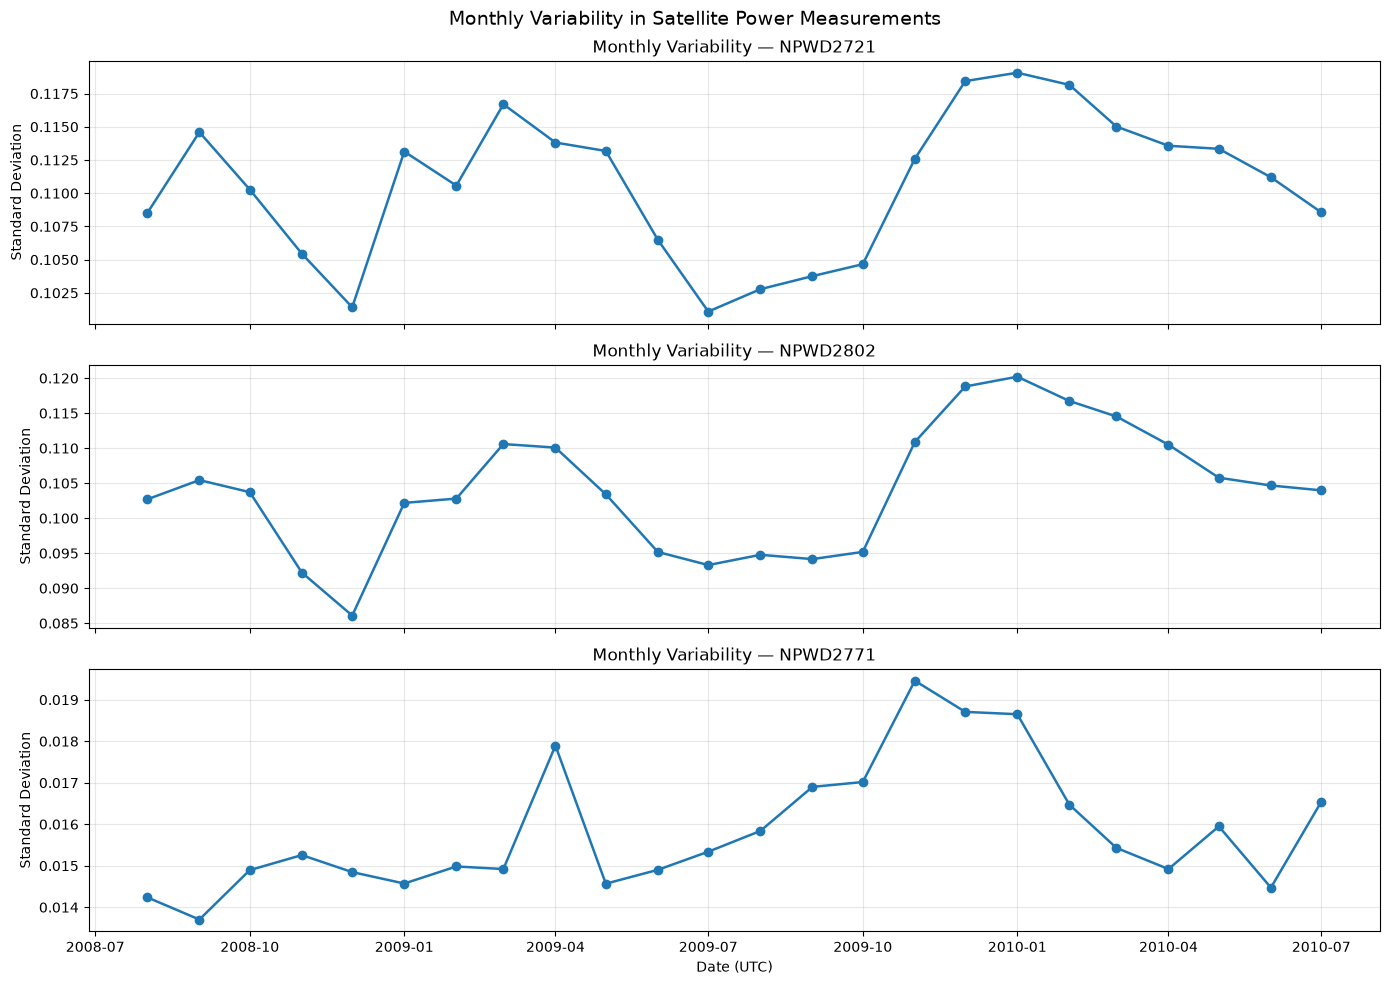

In [24]:

# Section 1.15.4 — Monthly Variability Analysis

# Reuse the existing satellite power dataset
selected_variables = ["NPWD2721", "NPWD2802", "NPWD2771"]

# Convert existing timestamps to UTC datetime
power_dates = pd.to_datetime(
    df_power["ut_ms"], unit="ms", utc=True
)

# Calculate monthly standard deviation
monthly_variability = (
    df_power[selected_variables]
    .set_axis(power_dates)
    .resample("MS")
    .std()
)

# Visualize monthly variability
fig, axes = plt.subplots(
    3, 1, figsize=(14, 10), sharex=True
)

for ax, variable in zip(axes, selected_variables):
    ax.plot(
        monthly_variability.index,
        monthly_variability[variable],
        marker="o",
        linewidth=1.8
    )

    ax.set_title(f"Monthly Variability — {variable}")
    ax.set_ylabel("Standard Deviation")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date (UTC)")

fig.suptitle(
    "Monthly Variability in Satellite Power Measurements",
    fontsize=14
)

plt.tight_layout()
plt.show()


### Interpretation — Monthly Variability and Measurement Stability

The monthly standard deviation analysis reveals distinct variability patterns across the three selected satellite power measurements.

**NPWD2721:** Monthly standard deviation fluctuates between approximately 0.101 and 0.119. Higher variability is observed toward the end of 2009, while relatively stable measurement periods occur around mid-2009.

**NPWD2802:** Monthly standard deviation ranges from approximately 0.086 to 0.120, indicating more pronounced changes in measurement variability. The highest variability occurs around December 2009 and January 2010, suggesting increased fluctuations during this period.

**NPWD2771:** This variable exhibits lower absolute standard deviation, generally ranging between 0.014 and 0.020. A noticeable increase occurs in April 2009, followed by a peak around November 2009. Variability subsequently declines during 2010.

**Overall Findings:**

- NPWD2721 and NPWD2802 demonstrate broadly similar monthly variability patterns.
- NPWD2771 exhibits lower absolute variability but follows a somewhat different temporal pattern.
- All three variables experience increased measurement variability during parts of late 2009.
- These fluctuations may reflect changes in satellite operating conditions, measurement behavior, or other underlying factors that require further investigation.

**Conclusion:** Monthly standard deviation provides additional insight into measurement stability beyond monthly averages. The findings highlight periods of increased variability that may be relevant for subsequent anomaly detection and satellite power performance analysis. Direct comparisons of relative stability would require accounting for differences in measurement scales.


## 1.16 Exploratory Data Analysis — Summary and Conclusions

### 1.16.1 Dataset Overview

The exploratory analysis examined 33 satellite power measurement variables, each containing 1,830,121 observations.

The dataset provides a foundation for understanding satellite electrical power behavior and investigating relationships between different power measurements.

### 1.16.2 Data Quality Assessment

The analysis identified:

- No missing values across the 33 power variables.
- No negative or zero values in the examined measurements.
- IQR-based outliers in 26 variables.
- NPWD2851 as the variable with the highest IQR outlier count (783,739).

These findings indicate that the dataset is complete for the examined variables. However, the large number of statistical outliers requires careful interpretation because unusual measurements may represent genuine satellite operating conditions.

### 1.16.3 Power Measurement Distributions

The distributions revealed distinct measurement patterns, including concentrated values, multiple peaks, and differences in variability.

These characteristics suggest that satellite power measurements may reflect different operating states rather than a single continuous operating condition.

### 1.16.4 Correlation Analysis

Pearson correlation analysis revealed generally weak linear relationships between many satellite power variables.

The strongest positive correlation was observed between NPWD2721 and NPWD2802 (r = 0.439).

The strongest negative correlation was observed between NPWD2451 and NPWD2771 (r = -0.617).

These relationships may provide useful information for subsequent feature selection and power behavior modeling.

### 1.16.5 Temporal Behavior

Time-series visualization revealed changes in satellite power measurements across the observation period.

Some variables exhibited substantial fluctuations, while others remained relatively stable with occasional deviations.

These patterns highlight the importance of considering temporal information when developing predictive models.

### 1.16.6 Monthly Trends and Variability

Monthly aggregation revealed changes in average power measurements and standard deviations over time.

NPWD2721 and NPWD2802 displayed similar monthly trends, consistent with their positive correlation.

NPWD2771 exhibited comparatively stable monthly averages, although periods of increased variability were observed.

### 1.16.7 Implications for AI Modeling

The exploratory findings suggest several considerations for subsequent modeling:

- Preserve temporal ordering during model development and evaluation.
- Investigate statistical outliers before applying any removal strategy.
- Consider relationships between correlated power variables.
- Account for differences in measurement scales and variability.
- Investigate operating-state changes when interpreting predictions.

### 1.16.8 Conclusion

The exploratory analysis established an initial understanding of satellite power data quality, statistical distributions, variable relationships, and temporal behavior.

These findings provide a foundation for the next phase of Dream-in-Orbit: preparing satellite telemetry data for AI-based modeling and simulation.
